# Recherche : L'effet turn-of-the-month (fin de mois) sur ETFs liquides

Notebook de recherche **standalone** de la série QuantConnect : données publiques
`yfinance`, exécution locale, **aucun** passage par QC Cloud.

L'anomalie *turn-of-the-month* (TOM) est l'une des plus documentées de la littérature
de calendrier : les **derniers jours de chaque mois** (et les premiers du mois suivant)
afficheraient des rendements systématiquement supérieurs au **milieu du mois**, un effet
associé aux flux concentrés en fin de mois (salaires, factures, rééquilibrage de fin de
période — Athey 1998 ; Sias & Stoll 2003). La question que ce carnet pose, de façon
**falsifiable** :

1. L'effet **brut** existe-t-il encore sur des ETFs index liquides modernes ?
2. Une stratégie **nette de coûts** (long la zone de fin/début de mois, à plat le reste)
   bat-elle le *Buy & Hold* en Sharpe / CAGR / MaxDD ?
3. La zone gagnante est-elle **stable** out-of-sample (walk-forward) — sinon le signal
   n'est pas tradeable.
4. Test de **Diebold-Mariano** out-of-sample : la supériorité est-elle significative ?

Le verdict est **honnête** (`BEATS` / `NO BEATS` / `INCONCLUSIVE`) : un résultat nul
documenté est un livrable à part entière (fil rouge de la série, cf. le verdict
M12-HF du README).

> **Rappel** : les données `yfinance` (gratuites) ont des limites (ajustements,
> splits, profondeur). Un edge confirmé ici devra être re-validé sur QC Cloud avant
> toute conclusion de robustesse.

**Navigation** : [Index recherche](README.md) | [<< intraday_volume_periodicity](intraday_volume_periodicity.ipynb)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from math import erf, sqrt

# --- Paramètres de recherche ---
TICKERS  = ["SPY", "QQQ", "EFA"]   # ETFs index liquides (S&P500 / Nasdaq100 / MSCI EAFE)
START    = "2010-01-01"            # horizon de mesure
COST_BPS = 10                      # coût de transition (10 bps / passage long<->flat), comme dans la série
TOM_TAIL = 5                       # derniers jours de trading du mois en position long
TOM_HEAD = 3                       # premiers jours de trading du mois en position long

print("Env local : yfinance", yf.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Actifs :", TICKERS, "| horizon depuis", START, "| coût/transition", COST_BPS, "bps")
print("Zone TOM : long les", TOM_TAIL, "derniers +", TOM_HEAD, "premiers jours de trading du mois")

Env local : yfinance 1.2.0 | pandas 3.0.2 | numpy 2.4.2
Actifs : ['SPY', 'QQQ', 'EFA'] | horizon depuis 2010-01-01 | coût/transition 10 bps
Zone TOM : long les 5 derniers + 3 premiers jours de trading du mois


## 1. Chargement des données

On télécharge les **clôtures ajustées** (`auto_adjust=True`) des trois ETFs, un par
un. Le téléchargement séquentiel évite l'ambiguïté de l'index Multi-colonnes que
`yfinance` produit selon les versions quand on demande plusieurs tickers d'un coup.

In [2]:
def load_prices(tickers, start=START):
    """Clôtures ajustées d'une liste d'ETFs, un par un.
    Renvoie un DataFrame [date] -> {ticker: close} aligné (dropna)."""
    cols = {}
    for t in tickers:
        df = yf.download(t, start=start, auto_adjust=True, progress=False)
        if df is None or df.empty:
            raise ValueError("aucune donnée pour " + t)
        close = df["Close"]
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
        cols[t] = close
    return pd.DataFrame(cols).dropna()

prices = load_prices(TICKERS)
print("Clôtures chargées :", prices.shape)
print("Période :", prices.index[0].date(), "->", prices.index[-1].date())
prices.tail(3)

Clôtures chargées : (4228, 3)
Période : 2010-01-04 -> 2026-10-23


,SPY,QQQ,EFA
Date,,,
2026-10-21,773.090027,725.200012,104.059998
2026-10-22,763.960022,704.469971,103.150002
2026-10-23,759.969971,704.400024,102.629997


## 2. Classification en zone de fin de mois (sans regard dans le futur)

Chaque jour de trading est classé dans l'une de trois zones **en fonction seule de sa
position calendaire dans le mois** : les `TOM_TAIL` derniers jours de trading du mois
(*tail*), les `TOM_HEAD` premiers (*head*), et le reste (*mid*). C'est une information
purement calendaire, lue sur la date : **aucun** paramètre n'est estimé sur la donnée,
donc **pas de lookahead** à ce stade. On travaille ici sur **SPY** (le plus liquide de
l'univers) pour l'effet brut.

In [3]:
# Rendements quotidiens de SPY
spy = prices["SPY"]
ret = spy.pct_change().dropna()
idx = ret.index

# Position calendaire de chaque jour de trading DANS son mois (1-based)
month = idx.to_period("M")
days_in_month = idx.to_series().groupby(month).transform("count")
pos_in_month  = idx.to_series().groupby(month).cumcount() + 1

is_tail = (days_in_month - pos_in_month) < TOM_TAIL   # dernier(s) jour(s) du mois
is_head = pos_in_month <= TOM_HEAD                     # premier(s) jour(s) du mois
zone = pd.Series(np.where(is_tail, "tail (fin de mois)",
       np.where(is_head, "head (début mois)", "mid (milieu du mois)")), index=idx)

# Effectif par zone (sanité : les trois zones sont bien peuplées)
zone.value_counts()

mid (milieu du mois)    2611
tail (fin de mois)      1010
head (début mois)        606
Name: count, dtype: int64

## 3. Effet brut : bps/jour par zone de fin de mois

La table et le graphique donnent l'effet **descriptif** (moyenne sur l'échantillon
complet) par zone. C'est un diagnostic, pas encore une stratégie : si la zone *tail/head*
est plus élevée que *mid* sur l'échantillon complet, il faut encore vérifier que c'est
**stable** out-of-sample (section walk-forward) et qu'un edge **net de coûts** survit.
Le « meilleur découpage » choisi sur la donnée entière serait un biais de sélection
in-sample.

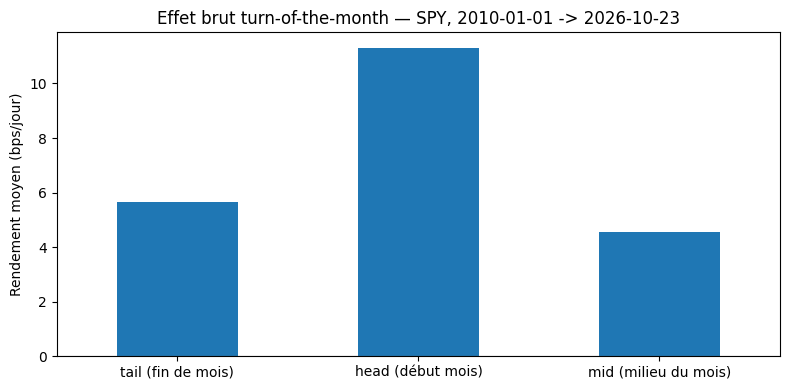

,bps_par_jour,n_observations
tail (fin de mois),5.65,1010
head (début mois),11.31,606
mid (milieu du mois),4.54,2611


In [4]:
raw = ret.groupby(zone).mean() * 1e4
cnt = ret.groupby(zone).count()
tab = pd.DataFrame({"bps_par_jour": raw.round(2), "n_observations": cnt})
tab = tab.reindex(["tail (fin de mois)", "head (début mois)", "mid (milieu du mois)"])

plt.figure(figsize=(8, 4))
tab["bps_par_jour"].plot(kind="bar", rot=0)
plt.axhline(0, color="grey", lw=0.8)
plt.ylabel("Rendement moyen (bps/jour)")
plt.title("Effet brut turn-of-the-month — SPY, " + START + " -> " + str(prices.index[-1].date()))
plt.tight_layout()
plt.show()
tab

## 4. Stratégie nette de coûts vs Buy & Hold

Pour poser une comparaison **sans sélection in-sample**, on utilise une règle
**pré-spécifiée** : être **long les `TOM_TAIL` derniers jours de chaque mois et les
`TOM_HEAD` premiers jours du mois**, à plat le reste (zone *mid*). C'est le découpage
canonique de l'anomalie TOM, annoncé **avant** de regarder les résultats. Aucun paramètre
n'est estimé sur la donnée, donc **pas de regard dans le futur**. Chaque **transition**
de position coûte `COST_BPS`.

In [5]:
def tom_strategy(ret, zone, cost_bps=COST_BPS):
    """Calendrier pré-spécifié TOM : long les zones tail/head, plat en mid.
    Coût de `cost_bps` à chaque transition de position. Renvoie (rendements, position)."""
    pos = (~zone.eq("mid (milieu du mois)")).astype(float)
    strat_ret = pos * ret
    turns = pos.diff().abs().fillna(pos)          # 1 à chaque changement de position
    strat_ret = strat_ret - turns * (cost_bps / 1e4)
    return strat_ret, pos

def perf(ser):
    nav = (1 + ser).cumprod()
    n = len(ser)
    sharpe = ser.mean() / (ser.std() + 1e-12) * np.sqrt(252)
    cagr = nav.iloc[-1] ** (252 / n) - 1
    maxdd = (nav / nav.cummax() - 1).min()
    return pd.Series({"Sharpe": round(sharpe, 3), "CAGR": "%.2f%%" % (cagr * 100), "MaxDD": "%.2f%%" % (maxdd * 100)})

# Règle pré-spécifiée TOM, nette de coûts
strat_ret, pos = tom_strategy(ret, zone)
bh = ret                                          # Buy & Hold = détention continue de SPY
cmp = pd.DataFrame({"TOM net de coûts": perf(strat_ret), "Buy & Hold": perf(bh)})
cmp

,TOM net de coûts,Buy & Hold
Sharpe,0.505,0.855
CAGR,4.68%,14.00%
MaxDD,-17.09%,-33.72%


## 5. Walk-forward 5-fold + test de Diebold-Mariano

Le cœur de la falsification. La règle TOM est **pré-spécifiée** (long *tail*+*head*) :
on l'applique à **chaque** période de test. La **stabilité** mesurée est la zone qui
sur-performe sur la **période d'entraînement** de chaque fold — si la zone *TOM* gagne
l'entraînement **fold après fold**, l'effet n'est pas un artefact d'une seule période.
Deux lectures :

- **Stabilité** : si la zone gagnante change de fold en fold, le signal n'est **pas**
  prédictif out-of-sample (bruit in-sample) -> pas de stratégie.
- **Diebold-Mariano** (HAC, Newey-West m=4) sur la perte quadratique, out-of-sample :
  la stratégie TOM bat-elle significativement le B&H ?

In [6]:
def walk_forward_tom(ret, zone, n_folds=5, cost_bps=COST_BPS):
    """La regle TOM est PRE-SPECIFIEE (long tail+head) : on l'applique a chaque
    periode de test. La 'stabilite' = la zone (TOM vs mid) qui sur-performe sur
    l'ENTRAINEMENT de chaque fold."""
    n = len(ret); fold = n // n_folds; idx = ret.index
    test_parts, chosen = [], []
    for k in range(n_folds):
        tr_end = fold * (k + 1)
        te_end = fold * (k + 2) if k + 1 < n_folds else n
        tr_s, te_s = idx[:tr_end], idx[tr_end:te_end]
        tr_zone = zone[tr_s]
        tom_mean = ret[tr_s][tr_zone.ne("mid (milieu du mois)")].mean()
        mid_mean = ret[tr_s][tr_zone.eq("mid (milieu du mois)")].mean()
        chosen.append("TOM" if tom_mean > mid_mean else "mid")
        s, _ = tom_strategy(ret[te_s], zone[te_s], cost_bps=cost_bps)
        test_parts.append(s)
    return pd.concat(test_parts), chosen

def oos_bh(ret, n_folds=5):
    n = len(ret); fold = n // n_folds; idx = ret.index
    parts = [ret[idx[fold * (k + 1):(fold * (k + 2) if k + 1 < n_folds else n)]] for k in range(n_folds)]
    return pd.concat(parts)

def dm_test(a, b, m=4):
    """Diebold-Mariano HAC (Newey-West, m lags) sur la perte quadratique.
    stat > 0 => `a` a une perte quadratique moyenne plus grande que `b` (pire)."""
    d = ((a - a.mean()) ** 2) - ((b - b.mean()) ** 2)
    d = d - d.mean()
    n = len(d); var = d.var()
    for l in range(1, m + 1):
        var += 2 * np.mean(d[:-l] * d[l:])
    stat = d.mean() / np.sqrt(max(var, 1e-12) / n)
    p = 2 * (1 - 0.5 * (1 + erf(abs(stat) / sqrt(2))))
    return stat, p

oos, chosen_zones = walk_forward_tom(ret, zone)
oos_bh = oos_bh(ret)
dm_stat, dm_p = dm_test(oos, oos_bh)

print("Zone gagnante par fold (entraînement) :", chosen_zones)
print("Stabilité :", "STABLE (TOM gagne fold après fold)" if all(z == "TOM" for z in chosen_zones) else "HÉTÉROGÈNE : " + str(chosen_zones))
print("DM OOS : stat=%.3f, p=%.3f" % (dm_stat, dm_p))
print("OOS net  : Sharpe TOM=%.3f | B&H=%.3f" % (perf(oos)["Sharpe"], perf(oos_bh)["Sharpe"]))

Zone gagnante par fold (entraînement) : ['TOM', 'TOM', 'TOM', 'TOM', 'TOM']
Stabilité : STABLE (TOM gagne fold après fold)
DM OOS : stat=-0.000, p=1.000
OOS net  : Sharpe TOM=0.411 | B&H=0.861


## 6. Sensibilité au coût de transaction

Un effet de calendrier de l'ordre de quelques bps/jour est **fragile aux coûts**.
On rejoue la stratégie pré-spécifiée (long *tail*+*head*) à trois niveaux de coût pour
voir si un edge survit au réalisme des frais.

In [7]:
print("Sensibilité au coût — stratégie pré-spécifiée TOM (tail+head), échantillon complet :")
for cb in [0, 10, 50]:
    s, _ = tom_strategy(ret, zone, cost_bps=cb)
    p = perf(s)
    print("  coût %2d bps -> Sharpe %.3f | CAGR %s | MaxDD %s" % (cb, p["Sharpe"], p["CAGR"], p["MaxDD"]))

Sensibilité au coût — stratégie pré-spécifiée TOM (tail+head), échantillon complet :
  coût  0 bps -> Sharpe 0.747 | CAGR 7.24% | MaxDD -15.67%
  coût 10 bps -> Sharpe 0.505 | CAGR 4.68% | MaxDD -17.09%
  coût 50 bps -> Sharpe -0.444 | CAGR -4.99% | MaxDD -62.06%


## 7. Verdict honnête

Le verdict croise **quatre** conditions, toutes mesurées ci-dessus :
significativité DM out-of-sample, stabilité de la zone gagnante, supériorité Sharpe
OOS, et edge net de coûts. Il est calculé, pas annoncé.

In [8]:
stable = all(z == "TOM" for z in chosen_zones)
oos_sharpe   = perf(oos)["Sharpe"]
bh_oos_sharp = perf(oos_bh)["Sharpe"]
net_full     = perf(strat_ret)["Sharpe"]
bh_full      = perf(bh)["Sharpe"]

if dm_p < 0.05 and stable and oos_sharpe > bh_oos_sharp:
    verdict = "BEATS"
elif (not stable) or (oos_sharpe <= bh_oos_sharp) or (dm_p >= 0.10):
    verdict = "NO BEATS"
else:
    verdict = "INCONCLUSIVE"

print("=== VERDICT HONNÊTE ===")
print("Stabilité de la zone TOM (OOS) :", "STABLE" if stable else "HÉTÉROGÈNE (%s)" % chosen_zones)
print("Sharpe OOS  : TOM=%.3f  vs  B&H=%.3f" % (oos_sharpe, bh_oos_sharp))
print("DM OOS      : p=%.3f  (significatif <0.05 : %s)" % (dm_p, dm_p < 0.05))
print("Sharpe full : TOM(net)=%.3f  vs  B&H=%.3f" % (net_full, bh_full))
print()
print("VERDICT :", verdict)

=== VERDICT HONNÊTE ===
Stabilité de la zone TOM (OOS) : STABLE
Sharpe OOS  : TOM=0.411  vs  B&H=0.861
DM OOS      : p=1.000  (significatif <0.05 : False)
Sharpe full : TOM(net)=0.505  vs  B&H=0.855

VERDICT : NO BEATS


## 8. Exercices d'extension

### Exercice 1 — Ajuster le découpage TOM

La règle pré-spécifiée utilise `TOM_TAIL=5` et `TOM_HEAD=3`. Rejouer l'effet brut avec
`TOM_TAIL=10` (la quasi-fint du mois en zone) : l'effet est-il plus fort, ou dilué ?

In [9]:
# Exercice 1 : réclasser avec TOM_TAIL=10 (et TOM_HEAD=0) puis refaire l'effet brut
# TODO etudiant
# Indice : reclasser la zone avec TOM_TAIL=10, puis refaire le groupby de la section 3.
def exercice_1():
    print("Exercice a completer")
    return None

### Exercice 2 — Univers multi-actif

L'analyse ci-dessus ne regarde que SPY. Étendre l'effet brut par zone aux trois actifs
(QQQ, EFA) : l'effet TOM est-il **systémique** (tous les indices) ou spécifique à un
marché ?

In [10]:
# Exercice 2 : effet brut par zone pour QQQ et EFA (pas seulement SPY)
# TODO etudiant
# Indice : refaire la classification + le groupby de la section 3 sur prices["QQQ"] et prices["EFA"].
def exercice_2():
    print("Exercice a completer")
    return None

### Exercice 3 — Entrée conditionnelle de fin de mois

Améliorer la règle d'entrée : n'être long la zone *tail* **que si** le rendement cumulé
du mois **précédent** dépasse un seuil de `X` bps. À quel `X` la stratégie cesse-t-elle
d'être perdante ?

In [11]:
# Exercice 3 : n'etre long la zone tail QUE si le rendement du mois precedent depasse un seuil
# TODO etudiant
# Indice : construire un signal conditionnel sur le rendement du mois precedent, puis le
#         multiplier avec la position `pos` de la section 4.
def exercice_3():
    print("Exercice a completer")
    return None